# Alice-Gen: A Comparative Study of RNN Architectures for Next-Word Prediction and Text Generation
**Course:** Foundations of Generative AI (ICT4403), Assignment 2
**Name:** Mihika Bardhan  |  **Reg No:** 230953122

**Objective:** Build word-level autoregressive next-word predictors with four recurrent architectures, train them under identical conditions, compare them quantitatively and qualitatively, and study the effect of sampling temperature on generated text.

**Dataset:** *Alice's Adventures in Wonderland* by Lewis Carroll (Project Gutenberg #11) - https://www.gutenberg.org/ebooks/11

## 0. Setup

In [1]:
import os, re, time, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
os.makedirs("outputs", exist_ok=True)
print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 1. Dataset: loading, characteristics, preprocessing

In [2]:
# Download the book from Project Gutenberg (plain text)
!wget -q -O alice.txt https://www.gutenberg.org/cache/epub/11/pg11.txt

raw = open("alice.txt", encoding="utf-8-sig").read().replace("\r", "")

# Strip the Project Gutenberg header and licence footer
start = raw.find("*** START OF")
start = raw.find("\n", start) + 1
end = raw.find("*** END OF")
text = raw[start:end]

# Normalise curly quotes / dashes
text = (text.replace("\u2019", "'").replace("\u2018", "'")
            .replace("\u201c", '"').replace("\u201d", '"')
            .replace("\u2014", " ").replace("_", ""))
print("Characters:", len(text))
print(text[:400])

Characters: 144164

[Illustration]




Alice's Adventures in Wonderland

by Lewis Carroll

THE MILLENNIUM FULCRUM EDITION 3.0

Contents

 CHAPTER I.     Down the Rabbit-Hole
 CHAPTER II.    The Pool of Tears
 CHAPTER III.   A Caucus-Race and a Long Tale
 CHAPTER IV.    The Rabbit Sends in a Little Bill
 CHAPTER V.     Advice from a Caterpillar
 CHAPTER VI.    Pig and Pepper
 CHAPTER VII.   A Mad Tea-Party
 CHAPTER V


Total tokens        : 31281
Unique tokens       : 2640
Sentences (approx.) : 1654
Top 15 tokens       : [(',', 2427), ('the', 1651), ('.', 999), ('and', 874), ('to', 729), ('a', 637), ('she', 541), ('it', 530), ('of', 515), ('said', 462), ('!', 451), ('i', 411), ('alice', 386), ('in', 370), ('you', 365)]


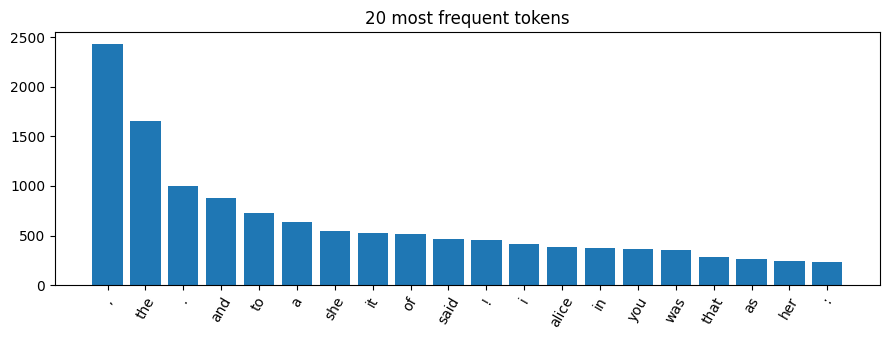

In [3]:
# Tokenisation: lowercase words (keeping apostrophes) + basic punctuation as separate tokens
def tokenize(t):
    return re.findall(r"[a-z]+(?:'[a-z]+)?|[.,!?;:]", t.lower())

tokens = tokenize(text)
counts = Counter(tokens)

print("Total tokens        :", len(tokens))
print("Unique tokens       :", len(counts))
print("Sentences (approx.) :", sum(counts[p] for p in ".!?"))
print("Top 15 tokens       :", counts.most_common(15))

top = counts.most_common(20)
plt.figure(figsize=(9, 3.5))
plt.bar([w for w, _ in top], [c for _, c in top])
plt.xticks(rotation=60); plt.title("20 most frequent tokens"); plt.tight_layout()
plt.savefig("outputs/token_frequency.png", dpi=150); plt.show()

In [4]:
# Vocabulary (capped). Index 0 = <pad>, index 1 = <unk>
MAX_VOCAB = 3000
itos = ["<pad>", "<unk>"] + [w for w, _ in counts.most_common(MAX_VOCAB - 2)]
stoi = {w: i for i, w in enumerate(itos)}
VOCAB = len(itos)
ids = np.array([stoi.get(w, 1) for w in tokens], dtype="int32")
print("Vocab size:", VOCAB, "| token coverage:", round(float((ids != 1).mean()) * 100, 2), "%")

Vocab size: 2642 | token coverage: 100.0 %


### Input-target sequences
A sliding window of `SEQ_LEN` tokens is the input and the **next token** is the target:  
`[w1 ... w20] -> w21`, `[w2 ... w21] -> w22`, ...  
The split is **chronological** (first 90% train, last 10% validation) so overlapping windows do not leak between the two sets.

In [5]:
SEQ_LEN = 20
X = np.stack([ids[i:i + SEQ_LEN] for i in range(len(ids) - SEQ_LEN)])
y = ids[SEQ_LEN:]

split = int(0.9 * len(X))
X_train, y_train = X[:split], y[:split]
X_val,   y_val   = X[split:], y[split:]
print("X:", X.shape, "y:", y.shape, "| train:", len(X_train), "val:", len(X_val))

print("\nExample input :", " ".join(itos[i] for i in X_train[100]))
print("Example target:", itos[y_train[100]])

X: (31261, 20) y: (31261,) | train: 28134 val: 3127

Example input : evidence chapter i . down the rabbit hole alice was beginning to get very tired of sitting by her sister
Example target: on


## 2. Models (identical except for the recurrent layer)

In [6]:
EMB, UNITS, DROPOUT = 128, 128, 0.3
BATCH, EPOCHS, LR = 128, 25, 1e-3
KINDS = ["SimpleRNN", "BiRNN", "LSTM", "GRU"]

def build_model(kind):
    tf.keras.backend.clear_session()
    tf.random.set_seed(SEED)
    rnn = {
        "SimpleRNN": lambda: layers.SimpleRNN(UNITS),
        "BiRNN":     lambda: layers.Bidirectional(layers.SimpleRNN(UNITS)),
        "LSTM":      lambda: layers.LSTM(UNITS),
        "GRU":       lambda: layers.GRU(UNITS),
    }[kind]()
    m = models.Sequential([
        layers.Input(shape=(SEQ_LEN,)),
        layers.Embedding(VOCAB, EMB),
        rnn,
        layers.Dropout(DROPOUT),
        layers.Dense(VOCAB, activation="softmax"),
    ], name=kind)
    m.compile(optimizer=tf.keras.optimizers.Adam(LR),
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy", tf.keras.metrics.SparseTopKCategoricalAccuracy(k=5, name="top5")])
    return m

for k in KINDS:
    print(k, "parameters:", f"{build_model(k).count_params():,}")

SimpleRNN parameters: 711,890
BiRNN parameters: 1,082,962
LSTM parameters: 810,578
GRU parameters: 778,066


## 3. Training (same seed, data, optimizer, batch size, max epochs, early stopping)

In [7]:
rows, histories, trained = [], {}, {}

for kind in KINDS:
    print(f"\n===== Training {kind} =====")
    model = build_model(kind)
    es = callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)
    t0 = time.time()
    h = model.fit(X_train, y_train, validation_data=(X_val, y_val),
                  epochs=EPOCHS, batch_size=BATCH, callbacks=[es], verbose=2)
    train_time = time.time() - t0

    val_loss, val_acc, val_top5 = model.evaluate(X_val, y_val, verbose=0)
    best = int(np.argmin(h.history["val_loss"]))
    epochs_run = len(h.history["loss"])
    rows.append({
        "Model": kind,
        "Params": model.count_params(),
        "Epochs run": epochs_run,
        "Best epoch": best + 1,
        "Train loss": h.history["loss"][best],
        "Val loss": val_loss,
        "Val perplexity": float(np.exp(val_loss)),
        "Val acc (top-1)": val_acc,
        "Val acc (top-5)": val_top5,
        "Train time (s)": train_time,
        "Sec/epoch": train_time / epochs_run,
    })
    histories[kind] = h.history
    trained[kind] = model
    model.save(f"outputs/{kind}.keras")


===== Training SimpleRNN =====
Epoch 1/25
220/220 - 11s - 50ms/step - accuracy: 0.0709 - loss: 6.0691 - top5: 0.1962 - val_accuracy: 0.0841 - val_loss: 5.8506 - val_top5: 0.2405
Epoch 2/25
220/220 - 1s - 6ms/step - accuracy: 0.0982 - loss: 5.5656 - top5: 0.2488 - val_accuracy: 0.1343 - val_loss: 5.5783 - val_top5: 0.2990
Epoch 3/25
220/220 - 1s - 5ms/step - accuracy: 0.1263 - loss: 5.2102 - top5: 0.2991 - val_accuracy: 0.1471 - val_loss: 5.4018 - val_top5: 0.3217
Epoch 4/25
220/220 - 1s - 5ms/step - accuracy: 0.1459 - loss: 4.9356 - top5: 0.3314 - val_accuracy: 0.1509 - val_loss: 5.3067 - val_top5: 0.3383
Epoch 5/25
220/220 - 1s - 5ms/step - accuracy: 0.1620 - loss: 4.7050 - top5: 0.3579 - val_accuracy: 0.1529 - val_loss: 5.2474 - val_top5: 0.3476
Epoch 6/25
220/220 - 1s - 6ms/step - accuracy: 0.1772 - loss: 4.5084 - top5: 0.3831 - val_accuracy: 0.1615 - val_loss: 5.2189 - val_top5: 0.3553
Epoch 7/25
220/220 - 1s - 6ms/step - accuracy: 0.1896 - loss: 4.3291 - top5: 0.4039 - val_accura

## 4. Quantitative evaluation

In [8]:
results = pd.DataFrame(rows).set_index("Model")
results.round(4).to_csv("outputs/results_table.csv")
results.round(4)

,Params,Epochs run,Best epoch,Train loss,Val loss,Val perplexity,Val acc (top-1),Val acc (top-5),Train time (s),Sec/epoch
Model,,,,,,,,,,
SimpleRNN,711890,10,7,4.3291,5.2128,183.6082,0.1663,0.3569,21.3246,2.1325
BiRNN,1082962,8,5,4.4439,5.2750,195.3960,0.1538,0.3550,19.7881,2.4735
LSTM,810578,15,12,4.4173,5.3509,210.7991,0.1644,0.3588,32.2472,2.1498
GRU,778066,11,8,4.1802,5.1404,170.7880,0.1807,0.3786,19.7508,1.7955


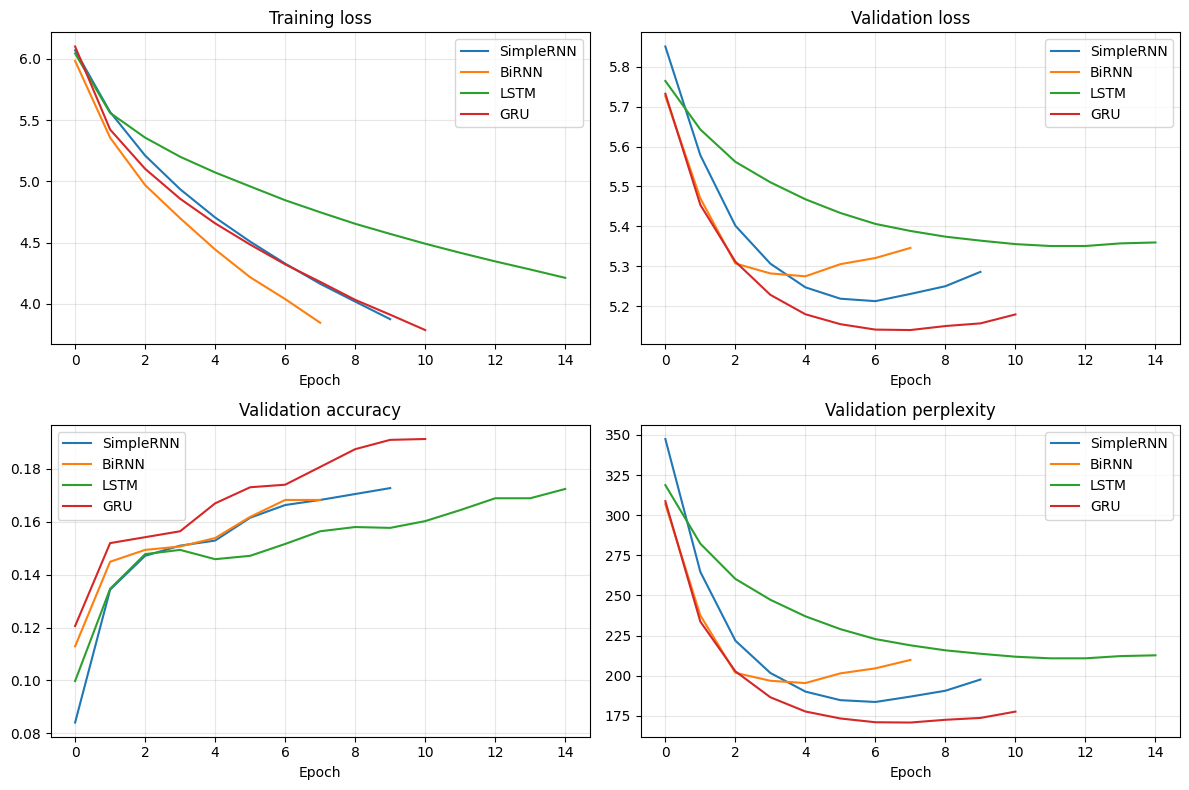

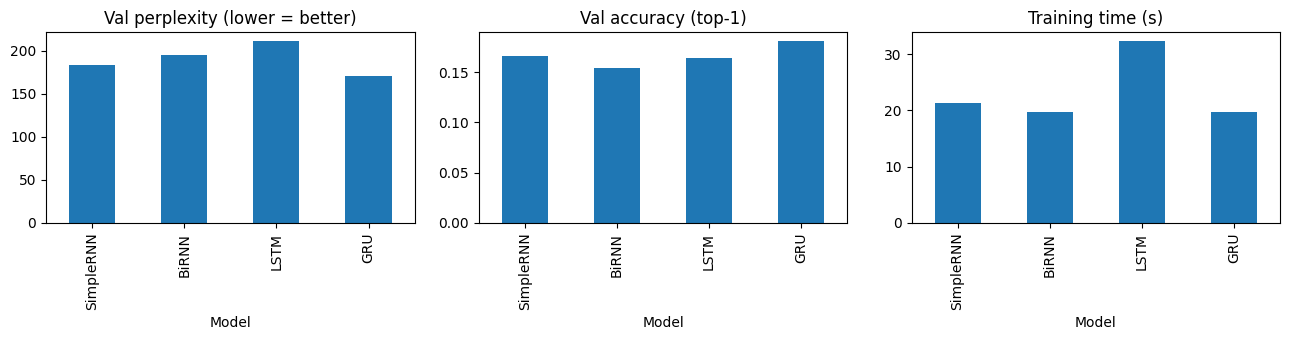

In [9]:
colors = {"SimpleRNN": "tab:blue", "BiRNN": "tab:orange", "LSTM": "tab:green", "GRU": "tab:red"}
fig, ax = plt.subplots(2, 2, figsize=(12, 8))
for k in KINDS:
    h = histories[k]
    ax[0, 0].plot(h["loss"], label=k, color=colors[k])
    ax[0, 1].plot(h["val_loss"], label=k, color=colors[k])
    ax[1, 0].plot(h["val_accuracy"], label=k, color=colors[k])
    ax[1, 1].plot(np.exp(h["val_loss"]), label=k, color=colors[k])
for a, t in zip(ax.ravel(), ["Training loss", "Validation loss", "Validation accuracy", "Validation perplexity"]):
    a.set_title(t); a.set_xlabel("Epoch"); a.legend(); a.grid(alpha=.3)
plt.tight_layout(); plt.savefig("outputs/training_curves.png", dpi=150); plt.show()

fig, ax = plt.subplots(1, 3, figsize=(13, 3.5))
results["Val perplexity"].plot.bar(ax=ax[0], title="Val perplexity (lower = better)")
results["Val acc (top-1)"].plot.bar(ax=ax[1], title="Val accuracy (top-1)")
results["Train time (s)"].plot.bar(ax=ax[2], title="Training time (s)")
plt.tight_layout(); plt.savefig("outputs/metric_comparison.png", dpi=150); plt.show()

## 5. Text generation with temperature sampling

In [10]:
def encode_seed(s):
    w = [stoi.get(x, 1) for x in tokenize(s)][-SEQ_LEN:]
    return [0] * (SEQ_LEN - len(w)) + w          # left-pad with <pad>

def detok(words):
    return re.sub(r" ([.,!?;:])", r"\1", " ".join(words))

def generate(model, seed, temperature, n_words=50, rng=None):
    rng = rng or np.random.default_rng(SEED)
    cur = encode_seed(seed)
    out = []
    for _ in range(n_words):
        p = model(np.array([cur]), training=False).numpy()[0].astype("float64")
        logp = np.log(np.clip(p, 1e-12, None))
        logp[[0, 1]] = -np.inf                     # never sample <pad> / <unk>
        logp = logp / temperature
        logp -= logp.max()
        q = np.exp(logp); q /= q.sum()
        nxt = int(rng.choice(len(q), p=q))
        out.append(itos[nxt])
        cur = cur[1:] + [nxt]
    return out

SEEDS = [
    "alice was beginning to get very tired of sitting",
    "the queen said to the",
    "she opened the door and found",
    "i do not know what you mean said the",
]
TEMPS = [0.5, 1.0, 1.5]
N_WORDS = 50

def ngram_stats(words):
    distinct1 = len(set(words)) / len(words)
    bi = list(zip(words, words[1:]));          distinct2 = len(set(bi)) / len(bi)
    tri = list(zip(words, words[1:], words[2:])); rep3 = 1 - len(set(tri)) / len(tri)
    return distinct1, distinct2, rep3

gen_rows = []
for kind in KINDS:
    for T in TEMPS:
        for s in SEEDS:
            words = generate(trained[kind], s, T, N_WORDS, rng=np.random.default_rng(SEED))
            d1, d2, r3 = ngram_stats(words)
            gen_rows.append({"Model": kind, "Temp": T, "Seed": s, "Text": detok(words),
                             "Distinct-1": d1, "Distinct-2": d2, "Repeated-trigram rate": r3})
gen = pd.DataFrame(gen_rows)
gen.to_csv("outputs/generated_samples.csv", index=False)

with open("outputs/generated_samples.txt", "w", encoding="utf-8") as f:
    for T in TEMPS:
        for s in SEEDS:
            f.write(f"\n=== Temperature {T} | Seed: '{s}' ===\n")
            for kind in KINDS:
                f.write(f"[{kind}] {s} {gen[(gen.Model==kind)&(gen.Temp==T)&(gen.Seed==s)].Text.iloc[0]}\n")
print("Saved outputs/generated_samples.txt")

Saved outputs/generated_samples.txt


In [11]:
# Show all samples, grouped by temperature and seed
for T in TEMPS:
    for s in SEEDS:
        print(f"\n=== Temperature {T} | Seed: '{s}' ===")
        for kind in KINDS:
            t = gen[(gen.Model == kind) & (gen.Temp == T) & (gen.Seed == s)].Text.iloc[0]
            print(f"[{kind:9s}] {s} -> {t}")


=== Temperature 0.5 | Seed: 'alice was beginning to get very tired of sitting' ===
[SimpleRNN] alice was beginning to get very tired of sitting -> on the chimney, and call a queen, and she found it and very little of the distance, and she spoke to see the gryphon, and she could never to be a little way to be down, and she was now to be a little way
[BiRNN    ] alice was beginning to get very tired of sitting -> it. if it was going to herself, and she tried to work, and she was out of the other things not! and she said the mouse. i'm the queen, and she was a little moment she had not off to the hatter. the
[LSTM     ] alice was beginning to get very tired of sitting -> on the dance. the gloves of the queen, and then it had not. i is her head! said alice. you know. the queen was very snatch and the rabbit, and she was not a large moment, said alice, and she said
[GRU      ] alice was beginning to get very tired of sitting -> on the window, and began to herself, and she tried to herself,

## 6. Diversity / repetition analysis

Distinct-1  Distinct-2  Repeated-trigram rate
Model     Temp                                               
BiRNN     0.5        0.590       0.867                  0.036
          1.0        0.795       1.000                  0.000
          1.5        0.945       1.000                  0.000
GRU       0.5        0.580       0.832                  0.068
          1.0        0.810       0.985                  0.000
          1.5        0.890       1.000                  0.000
LSTM      0.5        0.595       0.862                  0.047
          1.0        0.810       0.995                  0.000
          1.5        0.925       1.000                  0.000
SimpleRNN 0.5        0.555       0.816                  0.089
          1.0        0.805       0.995                  0.000
          1.5        0.945       1.000                  0.000

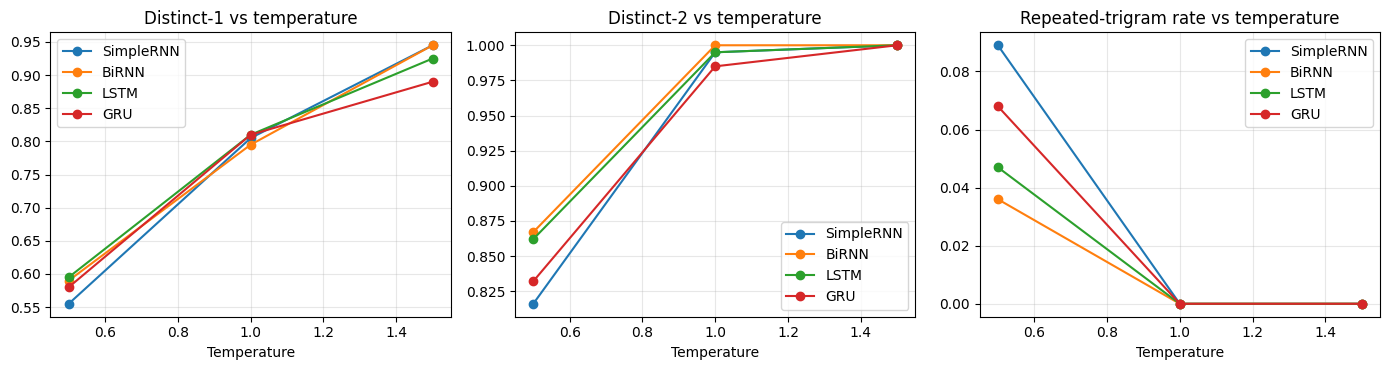

In [12]:
summary = gen.groupby(["Model", "Temp"])[["Distinct-1", "Distinct-2", "Repeated-trigram rate"]].mean().round(3)
summary.to_csv("outputs/generation_metrics.csv")
display(summary)

fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
for col, a in zip(["Distinct-1", "Distinct-2", "Repeated-trigram rate"], ax):
    for k in KINDS:
        d = summary.loc[k][col]
        a.plot(d.index, d.values, marker="o", label=k, color=colors[k])
    a.set_title(col + " vs temperature"); a.set_xlabel("Temperature"); a.grid(alpha=.3); a.legend()
plt.tight_layout(); plt.savefig("outputs/temperature_analysis.png", dpi=150); plt.show()

## 7. Analysis

**7.1 Quantitative comparison** - Which model has the lowest validation loss / perplexity and highest accuracy? Which trained fastest? Which overfit earliest (compare train vs val loss and best epoch)? Mention parameter counts.

**7.2 Qualitative comparison** - For each model: coherence, diversity, contextual consistency (does it stay on topic / keep sensible grammar?), repetition (loops like "the the the" or repeated phrases).

**7.3 Temperature analysis** - Low (0.5): ...  Medium (1.0): ...  High (1.5): ...  Use the Distinct-1/2 and repeated-trigram numbers above as evidence.

**7.4 Best model** - Naming one model and justify it using both the numbers and the generated text.



## 5. Results (validation set, best epoch restored)

| Model | Best epoch | Epochs run | Train loss | Val loss | Val perplexity | Val acc (top-1) | Val acc (top-5) | Train time (s) | Sec/epoch |
|---|---|---|---|---|---|---|---|---|---|
| SimpleRNN | 7 | 10 | 4.329 | 5.213 | 183.6 | 16.63% | 35.69% | 21.3 | 2.13 |
| BiRNN | 5 | 8 | 4.444 | 5.275 | 195.4 | 15.38% | 35.50% | 19.8 | 2.47 |
| LSTM | 12 | 15 | 4.417 | 5.351 | 210.8 | 16.44% | 35.88% | 32.2 | 2.15 |
| **GRU** | 8 | 11 | 4.180 | **5.140** | **170.8** | **18.07%** | **37.86%** | 19.8 | **1.80** |

Perplexity = exp(validation loss). A uniform guess over the 2,642-token vocabulary would give a perplexity of about 2,642, so all models learn real structure.

![training curves](outputs/training_curves.png)
![metric comparison](outputs/metric_comparison.png)

## 6. Model comparison and evaluation

**Quantitative.**
- **GRU** is best on every predictive metric: lowest validation loss (5.14) and perplexity (170.8), highest top-1 (18.1%) and top-5 (37.9%) accuracy. It was also the cheapest per epoch (1.80 s) and, together with BiRNN, had the shortest total training time (about 19.8 s).
- **SimpleRNN** came second (perplexity 183.6), which is notable given it has no gating, and suggests the 20-word context is short enough that vanishing gradients are not a major problem here.
- **BiRNN** has the most parameters (1.08M) and overfitted fastest: its validation loss was lowest at epoch 5 and then rose. Reading the 20-word context in both directions adds capacity, but no new information for predicting a *future* word.
- **LSTM** learned slowest: its training loss was still falling at 4.2 when it stopped, and its validation loss plateaued at 5.35, the highest of the four. It overfitted least, but never reached a low validation loss, so with this small dataset, learning rate and epoch budget it was the weakest. This should not be read as LSTM being inherently worse.
- The differences are modest (perplexity 171-211) and come from a single run per model (seed 42), so rankings between close models (e.g. SimpleRNN vs BiRNN) could change with another seed. Train time includes the three patience epochs after the best epoch and one-off first-epoch overhead.

**Qualitative (generated text, see `outputs/generated_samples.txt`).** At a low temperature all four models produce locally grammatical, book-like phrases ("said alice", "the gryphon", "the mock turtle"), but none stays coherent for 50 words; they drift into generic loops such as "and she was a little way ... and she was a little tone". GRU's output read most naturally and kept dialogue structure best, e.g. *"i don't know, said alice. i hardly think you know. the queen was very ..."* and *"she went on: i shall be no use about it. i don't know, said alice."* SimpleRNN showed the most repetition ("a little little height", "a little little voice"). LSTM was more erratic in word choice ("i is her head!", "very snatch") and, for two different seeds, converged onto the same continuation (*"...as she could not a little were pig, and she felt what at the first..."*), showing it falling into one high-probability path regardless of seed. BiRNN was the most varied at low temperature but least consistent in grammar ("a little going in her head and turned was").

## 7. Sampling-temperature analysis
Four shared seed sequences x three temperatures (0.5, 1.0, 1.5), 50 generated words each. Values are means over the four seeds (Distinct-1 / Distinct-2 = unique unigram / bigram ratio; Rep-3 = fraction of repeated trigrams).

| Model | T=0.5 (D1 / D2 / Rep-3) | T=1.0 | T=1.5 |
|---|---|---|---|
| SimpleRNN | 0.555 / 0.816 / 0.089 | 0.805 / 0.995 / 0.000 | 0.945 / 1.000 / 0.000 |
| BiRNN | 0.590 / 0.867 / 0.036 | 0.795 / 1.000 / 0.000 | 0.945 / 1.000 / 0.000 |
| LSTM | 0.595 / 0.862 / 0.047 | 0.810 / 0.995 / 0.000 | 0.925 / 1.000 / 0.000 |
| GRU | 0.580 / 0.832 / 0.068 | 0.810 / 0.985 / 0.000 | 0.890 / 1.000 / 0.000 |

![temperature analysis](outputs/temperature_analysis.png)

- **T = 0.5 (conservative):** the most coherent text (fluent phrases, correct dialogue tags) but also the most repetitive: lowest diversity (Distinct-1 about 0.55-0.60) and the only setting with repeated trigrams (3.6-8.9%). The model sticks to high-probability phrases such as "and she was a little ...".
- **T = 1.0 (balanced by the numbers, not by the text):** repetition disappears and diversity jumps (Distinct-1 about 0.80), but coherence drops sharply. Character names and dialogue tags survive, while grammar and meaning break down ("remark. serpent. she doubtful good cause ...").
- **T = 1.5 (random):** near-maximum diversity (Distinct-1 0.89-0.95) but the text is word salad with no coherence ("usually song within confused much likes person already up lessons ...").
- **Caveat on the metrics:** Distinct-2 and Rep-3 saturate at T >= 1.0 (about 1.0 and 0.0), so they no longer discriminate between models there; high diversity at high temperature reflects randomness, not quality. Differences of about 0.01-0.02 between models are within noise for 4 x 50 generated words. Coherence and contextual consistency were judged by reading the samples, which is subjective.
- **Trade-off:** lower temperature buys coherence at the cost of repetition; higher temperature buys diversity at the cost of coherence. For this dataset a value between 0.5 and 1.0 (roughly 0.7-0.8, not tested here) is the likely sweet spot.
- **Across models:** GRU's diversity rises more slowly with temperature (Distinct-1 0.89 at T = 1.5 vs 0.93-0.95 for the others), i.e. its output distribution is sharper and it is less prone to sampling rare words.

## 8. Conclusion
**GRU is the most effective model for autoregressive generation on this dataset.** It has the lowest perplexity (170.8) and highest accuracy (18.1% top-1, 37.9% top-5), the lowest cost per epoch, and generated the most natural-sounding dialogue at a low temperature. The trade-off is slightly higher repetition than BiRNN/LSTM at T = 0.5 (6.8% repeated trigrams), which a slightly higher temperature removes. SimpleRNN was a strong, cheap baseline; BiRNN overfitted fastest; LSTM learned most slowly. Limitations: a small corpus (about 31k tokens), one training run per model, a small set of seed sequences, and front matter (contents list, chapter headings) left in the text; absolute text quality is limited, since no model stays coherent over long spans.


In [13]:
# (Colab only) bundle everything for download, then upload the files to GitHub
try:
    !zip -qr outputs.zip outputs
    from google.colab import files
    files.download("outputs.zip")
except Exception as e:
    print("Skipping download:", e)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>